# Dispersal traits in MetaIBM-Nemo

How to give a species Nemo's two dispersal traits, `fdisp` and `mdisp`, read them, and run the species in MetaIBM.

In sections 1-7 they are set at founding, inherited and mutated, but they move no one; in section 8 MetaIBM's dispersal reads them.

0. Basics
1. The dispersal traits
2. The seven disp parameters
3. One species with only disp
4. Founders
5. Parents -> offspring
6. Mutation
7. In MetaIBM's life cycle
8. Dispersal that reads disp
9. Summary

## 0. Basics

| | MetaIBM (Python) | Nemo (C++, called through pynemo) |
|---|---|---|
| keeps | the landscape: which individual sits where | the genes of every individual |
| decides | who dies, who breeds, where offspring settle | which genes a founder, an offspring or a clone gets |

| Word | Meaning |
|---|---|
| species | one `indfactory` per species: it makes every individual of the species from one set of Nemo parameters |
| individual | one `metaibm.individual`; its genes are stored in Nemo |
| founder | an individual initialized at the start |
| make_offspring() | an individual made from a mother and a father; IndFactory::makeOffsprg() |
| make_clone() | an asexual offspring: it gets its mother's genes; IndFactory::makeCloneOffsprg() |
| make_copy() | an individual copied from another individual with new nemo's id; Individual::operator=() |
| trait | a heritable property; here, a dispersal value |
| locus | the place in the genome that codes for one trait |
| allele | one copy of a locus. Each individual carries two; a sexual offspring gets one from its mother (maternal) and one from its father (paternal) |
| mutation | a random change of an allele, at birth |
| dispersal rate | the probability that an offspring leaves its birthplace |
| sd | standard deviation: how spread out a set of values is |

In [1]:
import os
import random
from itertools import product

import numpy as np
import matplotlib.pyplot as plt

import bootstrap_metaibm                    # puts the project root on sys.path: the metaibm package; pynemo comes from the conda env
import metaibm
from metaibm.indfactory import indfactory

from pynemo import _nemo
from pynemo.params import SimParameters

_nemo.cvar.SILENT_RUN = True                # no Nemo banner
os.makedirs('nemo_cache', exist_ok=True)    # Nemo writes its boot log there and does not create the directory itself
random.seed(1)
np.random.seed(1)

## 1. The dispersal traits

| | |
|---|---|
| `fdisp` | the dispersal rate of a female |
| `mdisp` | the dispersal rate of a male |
| who carries them | **every individual carries both, whatever its own sex**, like sex-limited genes: each sex uses only its own (in Nemo's dispersal), so a male carries `fdisp` without using it and passes it on to his offspring |
| loci and alleles | one locus per trait, two alleles per locus; each allele is a number in [0, 1] |
| the value | the dispersal rate = the mean of the two alleles |
| allele order | maternal first, paternal second (the other Nemo traits store the paternal one first) |
| who uses the value | in Nemo's own simulations, a female offspring leaves with probability = her `fdisp`, a male with probability = his `mdisp` (Nemo's life-cycle event `disperse_evoldisp`). MetaIBM never runs Nemo's life-cycle events; its own dispersal reads these values when you pass `use_disp_trait=True` (section 8) |

## 2. The seven disp parameters

**Careful: some wrong settings end Python itself -- see the table after the code below.**

Nemo is configured by parameter rows `key value`. In Python, a `pynemo.params.SimParameters` collects them: one `params.add(key, value)` per row; the `SimParameters` then goes to `indfactory(...)`.
A row you never add is unset. Never add a row with the value `None`: Nemo reads it as the flag `key 1`.

| Row | Required | Range | What it does |
|---|---|---|---|
| `disp_mutation_rate` | yes | [0, 1] | $\mu$: how often an allele mutates at birth (section 6) |
| `disp_mutation_mean` | yes | [0, 1] | $m$: the mean size of one mutation step, drawn from an exponential distribution (section 6) |
| `disp_init_rate` | no | [0, 1] | every founder allele of both traits = this value; if _UNSET, draw from Uniform(0, 1)|
| `disp_init_rate_fem` | no | [0, 1] | every founder `fdisp` allele = this value; only together with `_mal`; if _UNSET, draw from Uniform(0, 1)|
| `disp_init_rate_mal` | no | [0, 1] | every founder `mdisp` allele = this value; only together with `_fem`; if _UNSET, draw from Uniform(0, 1)|
| `disp_init_distribution` | no | 'normal' \| 'uniform' | founder alleles drawn at random; if _UNSET, `uniform` |
| `disp_init_dist_params` | with the row above | matrix | {{mean, sd}, ...}; two rows = one per trait: **row 0 -> `mdisp`, row 1 -> `fdisp`** (Nemo's own order: male = 0, female = 1); any other number of rows: row 0 for both. 'uniform' does not read it, but it must be set. e.g., `'{{0.7, 0.1}{0.3, 0.1}}'` |

- Which rows decide the founders:

```
disp_init_distribution set?  -- yes -->  random founders ('normal' or 'uniform'); any disp_init_rate* row is ignored
        | no
disp_init_rate* set?         -- yes -->  fixed founders: disp_init_rate, or disp_init_rate_fem + disp_init_rate_mal
        | no
nothing set                  ------->  'uniform'  → U(0, 1) 
```

- 'normal': each allele = mean + a normal draw with that sd, **drawn again until it falls in [0, 1]**.
- 'uniform': each allele is a uniform draw from [0, 1], whatever `disp_init_dist_params` holds.

Nemo has more dispersal rows (`dispersal_model`, `dispersal_rate`, `dispersal_cost`, ...); they belong to Nemo's life-cycle events, which MetaIBM never runs. Leave them unset.

The code below builds the rows of four species, one for each way to set the founders; the four share the two mutation rows.
`non_genetic` holds rows every Nemo simulation needs, even one that is never run, as here. What each of them does: [USER-MANUAL-quanti-parameters.md](../../quanti-examples/USER-MANUAL-quanti-parameters.md), section (1).

In [2]:
non_genetic = {                                    # Nemo boots one simulation per species to build its prototypes; it is never run
    'replicates':     1,
    'generations':    1,
    'patch_number':   1,
    'patch_capacity': 1,
    'aging':          1,
    'run_mode':       'silent',
    'root_dir':       'nemo_cache',
    'logfile':        'nemo_cache/nemo.log',
}

mutation = {                                       # required: without them Nemo builds no disp trait
    'disp_mutation_rate': 0.02,                    # mu
    'disp_mutation_mean': 0.05,                    # m: mutation step ~ Exponential(mean m), so its sd is also m
}

init = {                                                                   # four ways to set the founders, one species each
    'sp1': {'disp_init_rate': 0.5},                                        # every founder allele of both traits = 0.5
    'sp2': {'disp_init_rate_fem': 0.2, 'disp_init_rate_mal': 0.8},         # fdisp alleles 0.2, mdisp alleles 0.8 (both rows or neither)
    'sp3': {'disp_init_distribution': 'normal',
            'disp_init_dist_params':  '{{0.7, 0.1}{0.3, 0.1}}'},           # {mean, sd}: row 0 -> mdisp (MAL = 0), row 1 -> fdisp (FEM = 1)
    'sp4': {'disp_init_distribution': 'uniform',
            'disp_init_dist_params':  '{{0, 0}}'},                         # U(0, 1); must be set, is not read
}

def disp_params(species_id):
    ''' the Nemo rows of one species: boot rows + its own log name + mutation + its init rows -- no quanti '''
    params = SimParameters()
    for key, value in list(non_genetic.items()) + [('filename', species_id)] + list(mutation.items()) + list(init[species_id].items()):
        params.add(key, value)
    return params

## 3. Create a indfactory of a species with only disp trait (`mdisp`, `fdisp`)

`indfactory(species_id, pheno_name_ls, nemo_params, trait_keys, seed)` turns one species' rows into a factory of individuals.

- `pheno_name_ls=()`: the names of the quantitative traits (`quant`); this species has none.
- `trait_keys=('fdisp', 'mdisp')`: the traits the rows build. The disp rows always build both, so name both (one alone raises ValueError).
- `seed=1`: the same seed gives the same individuals at every run.

In [3]:
species = {species_id: indfactory(species_id, (), disp_params(species_id), trait_keys=('fdisp', 'mdisp'), seed=1) for species_id in init}
print(species['sp3'])

indfactory
  metaibm-info : species_id=sp3, pheno_names=(), minted=0, recycled=0
  nemo-info    : traits_index={'fdisp': 0, 'mdisp': 1}, seed=1


## 4. Founders

`make_founder(gender)` makes a founder. Two readers of `metaibm/individual.py` give its dispersal traits:

| Reader | Returns |
|---|---|
| `get_trait_value('fdisp')` | the dispersal rate: a float |
| `get_trait_alleles('fdisp', 'get_allele_value')` | the two alleles: an np.ndarray of shape (1, 2), maternal then paternal |

The same with `'mdisp'`. In `get_trait_alleles`, `'get_allele_value'` asks for the allele values (for disp it is the only choice); the result has shape (1, 2) -- one locus, two alleles -- and `[0]` takes that one row.

Below: 900 founders per species; at the end `recycle()` hands each one back to Nemo.

In [4]:
founders = {species_id: [factory.make_founder('female') for _ in range(900)] for species_id, factory in species.items()}

print('species  trait  allele mean  allele sd  allele min - max  value mean  value sd')
for species_id, individuals in founders.items():
    for key in ('fdisp', 'mdisp'):
        alleles = np.array([ind.get_trait_alleles(key, 'get_allele_value')[0] for ind in individuals])   # (900, 2)
        values  = np.array([ind.get_trait_value(key) for ind in individuals])                            # (900,)
        print('%-8s %-6s %11.4f %10.4f   %.4f - %.4f  %10.4f  %8.4f' % (species_id, key, alleles.mean(), alleles.std(), alleles.min(), alleles.max(), values.mean(), values.std()))

for individuals in founders.values():
    for ind in individuals:
        ind.recycle()                              # back into Nemo's recycling pool

species  trait  allele mean  allele sd  allele min - max  value mean  value sd
sp1      fdisp       0.5000     0.0000   0.5000 - 0.5000      0.5000    0.0000
sp1      mdisp       0.5000     0.0000   0.5000 - 0.5000      0.5000    0.0000
sp2      fdisp       0.2000     0.0000   0.2000 - 0.2000      0.2000    0.0000
sp2      mdisp       0.8000     0.0000   0.8000 - 0.8000      0.8000    0.0000
sp3      fdisp       0.3016     0.1000   0.0081 - 0.6254      0.3016    0.0721
sp3      mdisp       0.7012     0.0991   0.4009 - 0.9866      0.7012    0.0698
sp4      fdisp       0.4990     0.2917   0.0004 - 0.9999      0.4990    0.2062
sp4      mdisp       0.4957     0.2871   0.0001 - 0.9999      0.4957    0.1977


- A founder's two alleles are drawn independently, value sd = (allele sd) / $\sqrt{2}$.

## 5. Parents -> offspring

| Birth | Call | The newborn's disp alleles |
|---|---|---|
| founder | `indfactory.make_founder(gender)` | drawn from the init rows; never mutated |
| sexual | `indfactory.make_offspring(mother, father, gender)` | maternal = one of the mother's two alleles, paternal = one of the father's, each picked at random; then mutation |
| clone | `indfactory.make_clone(mother)` | the mother's two alleles, in the same order; then mutation |
| copy | `individual.make_copy()` | an exact copy with a new ID, no mutation |

Below: one sp3 family. `print(individual)` shows the ID, the sex and the parents; this species has no phenotype, hence `phenotype=(none)`.

In [5]:
sp3 = species['sp3']
mother = sp3.make_founder('female')
father = sp3.make_founder('male')
family = {
    'mother':            mother,
    'father':            father,
    'sexual_offspring':  sp3.make_offspring(mother, father, 'male'),    # SWIG <-- IndFactory::makeOffsprg()
    'asexual_offspring': sp3.make_clone(mother),                        # SWIG <-- IndFactory::makeCloneOffsprg()
    'copied_individual': father.make_copy(),                            # SWIG <-- Individual::operator=()
}
for name, ind in family.items():
    print(name, ind)
    for key in ('fdisp', 'mdisp'):
        print('    %s value = %.4f   alleles (maternal, paternal) = %s' % (key, ind.get_trait_value(key), np.round(ind.get_trait_alleles(key, 'get_allele_value')[0], 4).tolist()))

for ind in family.values():
    ind.recycle()

mother individual
  metaibm-info : species_id=sp3, age=0, pheno_names=()
  nemo-info    : id=3601, gender=female, phenotype=(none), founder
    fdisp value = 0.3494   alleles (maternal, paternal) = [0.3201, 0.3787]
    mdisp value = 0.7118   alleles (maternal, paternal) = [0.7476, 0.6761]
father individual
  metaibm-info : species_id=sp3, age=0, pheno_names=()
  nemo-info    : id=3602, gender=male, phenotype=(none), founder
    fdisp value = 0.3026   alleles (maternal, paternal) = [0.3108, 0.2944]
    mdisp value = 0.6583   alleles (maternal, paternal) = [0.6627, 0.654]
sexual_offspring individual
  metaibm-info : species_id=sp3, age=0, pheno_names=()
  nemo-info    : id=3603, gender=male, phenotype=(none), mother 3601, father 3602
    fdisp value = 0.3447   alleles (maternal, paternal) = [0.3787, 0.3108]
    mdisp value = 0.7008   alleles (maternal, paternal) = [0.7476, 0.654]
asexual_offspring individual
  metaibm-info : species_id=sp3, age=0, pheno_names=()
  nemo-info    : id=3604,

## 6. Mutation

At each birth (a clone or a sexual offspring, never a founder), each allele mutates with probability about $\mu$ (`disp_mutation_rate`), so each trait mutates a random number of times: on average $2\mu$ times.
One mutation picks one of the two alleles and moves it up or down by a step drawn from an exponential distribution with mean $m$ (`disp_mutation_mean`), so the step's sd is also $m$. An allele never leaves [0, 1]: a step past 0 or 1 stops exactly at 0 or 1.

Below: sp2's founder mother (`fdisp` 0.2, 0.2; `mdisp` 0.8, 0.8) is cloned again and again, until one clone carries a mutation and one has an allele stopped at 0 or 1.

In [6]:
# TODO(Nemo RandBool Biase): (32-bit `1 << num`) -> disp mutations: + (51.5%); - (47.5%)
sp2 = species['sp2']
mother = sp2.make_founder('female')
before = {key: mother.get_trait_alleles(key, 'get_allele_value')[0] for key in ('fdisp', 'mdisp')}

found = {'mutated': False, 'clamped': False}
clone_num = 0
while not all(found.values()):
    clone = sp2.make_clone(mother)
    clone_num += 1
    after = {key: clone.get_trait_alleles(key, 'get_allele_value')[0] for key in ('fdisp', 'mdisp')}
    
    mutated = any((after[key] != before[key]).any() for key in after)        # some allele changed
    clamped = any(np.isin(after[key], (0.0, 1.0)).any() for key in after)    # some allele sits at 0 or 1
    for what, hit in (('mutated', mutated), ('clamped', clamped)):
        if hit and not found[what]:
            found[what] = True
            changes = ['%s %s -> %s' % (key, before[key].tolist(), np.round(after[key], 4).tolist()) for key in after if (after[key] != before[key]).any()]
            print('first %s clone: #%d (id %d)  %s' % (what, clone_num, clone.individual_id, '; '.join(changes)))
    clone.recycle()
mother.recycle()

first mutated clone: #11 (id 3617)  mdisp [0.8, 0.8] -> [0.8, 0.7339]
first clamped clone: #43 (id 3649)  fdisp [0.2, 0.2] -> [0.2, 0.0]


Clone #11 carries one mutation: `mdisp` 0.8 -> 0.7339, a step of -0.0661. In clone #43 an `fdisp` allele moved below 0 and was clamped to exactly 0.

## 7. In MetaIBM's life cycle

MetaIBM's landscape: a metacommunity holds patches, a patch holds habitats, and a habitat is a grid of microsites with at most one individual each. One time step:

| Step | Call | What happens |
|---|---|---|
| death | `meta_dead_selection(0.1, None, method='neutral_uniform')` | every individual dies with probability 0.1, whatever its genes; the dead go back to Nemo |
| birth | asexual: `meta_asex_reproduce_mutate_into_offspring_pool(0.5)`; sexual: `meta_sex_reproduce_mutate_into_offspring_pool(1)` | asexual: 0.5 clones per individual; sexual: one offspring per random female-male pair. The offspring wait in an offspring pool |
| germination | `meta_local_germinate_from_offspring_and_immigrant_pool()` | offspring settle at random in the empty microsites |
| clear-up | `meta_clear_up_offspring_and_immigrant_pool()` | the offspring left without a microsite go back to Nemo |

A species without `quant` needs three choices:

| Choice | Why |
|---|---|
| founders placed by hand: `make_founder` + `habitat.add_individual` | `hab_initialize` matches species to habitats through a phenotype table; this species has no phenotype |
| `method='neutral_uniform'` | the only selection that reads no phenotype; `'niche_gaussian'` raises `KeyError('quant')` |
| `'asexual'` or `'sexual'`, not `'mix'` | under neutral selection every survivor counts as well adapted, so mix would only clone |

Here: four patches, one 30 × 30 habitat each, one species per patch; nobody leaves its patch. A habitat must have an environment: `env1` = 0.5 everywhere, never read.
The next cell defines the landscape, the founders, a printout of each species' dispersal rates and the life cycle; the two after it run 500 steps, asexual then sexual.

In [7]:
# No dispersal in this section: every species stays in its patch, so fdisp / mdisp are only set at founding, inherited and mutated.
#   Section 8 adds a dispersal step that reads them (use_disp_trait=True).
def build_landscape():
    ''' four patches, one 30 x 30 habitat each; patch k + 1 will hold species k + 1 '''
    meta_obj = metaibm.metacommunity(metacommunity_name='metacommunity')
    for k in range(4):
        patch_obj = metaibm.patch(patch_name='patch%d' % (k + 1), patch_index=k, location=(k // 2, k % 2))
        patch_obj.add_habitat(hab_name='h%d' % (k + 1), hab_index=0, hab_location=(k // 2, k % 2), num_env_types=1, env_types_name=('env1',),
                              mean_env_ls=[0.5], var_env_ls=[0.0], length=30, width=30, global_index=k)
        meta_obj.add_patch(patch_name='patch%d' % (k + 1), patch_object=patch_obj)
    return meta_obj

def fill_founders(meta_obj, reproduce_mode):
    ''' every microsite of patch k + 1 gets a founder of species k + 1: asexual -> all female, sexual -> a random gender '''
    for patch_obj, factory in zip(meta_obj.set.values(), species.values()):
        for h_object in patch_obj.set.values():
            for row, col in product(range(h_object.length), range(h_object.width)):
                gender = 'female' if reproduce_mode == 'asexual' else np.random.choice(('male', 'female'))
                h_object.add_individual(factory.make_founder(gender, home_habitat=h_object.global_index), row, col)

def print_disp(label, meta_obj):
    ''' each species' mean (sd) fdisp and mdisp over its living individuals '''
    rates = {}
    for patch_obj in meta_obj.set.values():
        for h_object in patch_obj.set.values():
            for row in h_object.set['microsite_individuals']:
                for ind in row:
                    if ind is not None:
                        for key in ('fdisp', 'mdisp'):
                            rates.setdefault(key, {}).setdefault(ind.species_id, []).append(ind.get_trait_value(key))
    print('%-9s n=%d' % (label, meta_obj.get_meta_individual_num()))
    for key, by_species in rates.items():
        print('    %s mean (sd): %s' % (key, '   '.join('%s %.3f (%.3f)' % (sp, np.mean(v), np.std(v)) for sp, v in sorted(by_species.items()))))

def run_life_cycle(reproduce_mode, all_time_step=500, print_every=100, base_dead_rate=0.1):
    ''' neutral selection -> reproduction -> germination -> recycle the offspring left without a microsite; RETURN: the metacommunity, still populated '''
    meta_obj = build_landscape()
    fill_founders(meta_obj, reproduce_mode)
    print_disp('founders', meta_obj)
    for time_step in range(1, all_time_step + 1):
        meta_obj.meta_dead_selection(base_dead_rate, None, method='neutral_uniform')        # reads no phenotype, no fitness width
        if reproduce_mode == 'asexual': meta_obj.meta_asex_reproduce_mutate_into_offspring_pool(0.5)   # indfactory.make_clone()
        else:                           meta_obj.meta_sex_reproduce_mutate_into_offspring_pool(1)      # indfactory.make_offspring()
        meta_obj.meta_local_germinate_from_offspring_and_immigrant_pool(is_remove=True)
        meta_obj.meta_clear_up_offspring_and_immigrant_pool()
        if time_step % print_every == 0:
            print_disp('t=%d' % time_step, meta_obj)
    return meta_obj

In [8]:
asexual_meta = run_life_cycle('asexual')

founders  n=3600
    fdisp mean (sd): sp1 0.500 (0.000)   sp2 0.200 (0.000)   sp3 0.302 (0.068)   sp4 0.505 (0.206)
    mdisp mean (sd): sp1 0.500 (0.000)   sp2 0.800 (0.000)   sp3 0.700 (0.071)   sp4 0.496 (0.205)
t=100     n=3600
    fdisp mean (sd): sp1 0.501 (0.023)   sp2 0.201 (0.019)   sp3 0.300 (0.065)   sp4 0.521 (0.176)
    mdisp mean (sd): sp1 0.499 (0.019)   sp2 0.800 (0.023)   sp3 0.722 (0.064)   sp4 0.462 (0.192)
t=200     n=3600
    fdisp mean (sd): sp1 0.500 (0.031)   sp2 0.202 (0.028)   sp3 0.311 (0.067)   sp4 0.516 (0.203)
    mdisp mean (sd): sp1 0.503 (0.030)   sp2 0.796 (0.026)   sp3 0.715 (0.059)   sp4 0.449 (0.191)
t=300     n=3600
    fdisp mean (sd): sp1 0.490 (0.046)   sp2 0.208 (0.037)   sp3 0.314 (0.072)   sp4 0.542 (0.190)
    mdisp mean (sd): sp1 0.506 (0.034)   sp2 0.802 (0.031)   sp3 0.710 (0.069)   sp4 0.435 (0.169)
t=400     n=3600
    fdisp mean (sd): sp1 0.491 (0.057)   sp2 0.213 (0.041)   sp3 0.311 (0.070)   sp4 0.538 (0.194)
    mdisp mean (sd): sp1

In [9]:
sexual_meta = run_life_cycle('sexual')

founders  n=3600
    fdisp mean (sd): sp1 0.500 (0.000)   sp2 0.200 (0.000)   sp3 0.298 (0.071)   sp4 0.497 (0.204)
    mdisp mean (sd): sp1 0.500 (0.000)   sp2 0.800 (0.000)   sp3 0.700 (0.074)   sp4 0.506 (0.207)
t=100     n=3600
    fdisp mean (sd): sp1 0.495 (0.027)   sp2 0.200 (0.016)   sp3 0.306 (0.069)   sp4 0.508 (0.184)
    mdisp mean (sd): sp1 0.499 (0.018)   sp2 0.799 (0.020)   sp3 0.713 (0.075)   sp4 0.493 (0.210)
t=200     n=3600
    fdisp mean (sd): sp1 0.501 (0.031)   sp2 0.203 (0.030)   sp3 0.285 (0.073)   sp4 0.498 (0.225)
    mdisp mean (sd): sp1 0.500 (0.030)   sp2 0.797 (0.028)   sp3 0.713 (0.077)   sp4 0.440 (0.213)
t=300     n=3600
    fdisp mean (sd): sp1 0.497 (0.033)   sp2 0.201 (0.033)   sp3 0.292 (0.073)   sp4 0.459 (0.216)
    mdisp mean (sd): sp1 0.501 (0.027)   sp2 0.790 (0.042)   sp3 0.731 (0.077)   sp4 0.454 (0.209)
t=400     n=3600
    fdisp mean (sd): sp1 0.502 (0.044)   sp2 0.199 (0.042)   sp3 0.297 (0.082)   sp4 0.453 (0.215)
    mdisp mean (sd): sp1

Nothing selects or moves the dispersal rates here: they change only by mutation and chance. sp1 and sp2 start with sd 0 and spread out.

## 8. Dispersal that reads disp

MetaIBM's dispersal functions read `fdisp` / `mdisp` when you pass `use_disp_trait=True`; with the defaults they disperse as before. Four keywords choose how:

| Scheme | Keywords | Who goes from patch i to patch j |
|---|---|---|
| 1 (default) | `use_disp_trait=False` | $e_{ij} \approx m_{ij} \times N_i$ individuals, all equally likely |
| 2 | `use_disp_trait=True, is_rescale=True` | the same number $e_{ij}$; each draw picks individual k with weight $v_k$ |
| 3 | `use_disp_trait=True, is_rescale=False` | each individual k goes with probability $v_k \times m_{ij}$ |
| 4 | `use_disp_trait=True, is_rescale=False, disp_cost=c` or `use_disp_trait=True, is_rescale=False, disp_cost=(c_fem, c_mal)` | as scheme 3; each leaver then dies on the way with probability c and goes back to Nemo |

The probability that individual k goes from patch i to patch j in one call:

$$
\text{Scheme 1:} \quad P(k: i \to j) = m_{ij}
$$

$$
\text{Scheme 2:} \quad P(k: i \to j) \approx m_{ij} \cdot N_i \cdot \frac{v_k}{\sum_{l \in i} v_l}
$$

$$
\text{Scheme 3:} \quad P(k: i \to j) = v_k \cdot m_{ij}
$$

$$
\text{Scheme 4:} \quad P(k: i \to j) = v_k \cdot m_{ij} \cdot (1 - c), \qquad P(k \text{ dies on the way}) = v_k \cdot m \cdot c
$$

- $v_k$: individual k's `fdisp`; with `sex_specific=True` a male reads `mdisp`.
- $m_{ij} = m \cdot \mathrm{Normalize}(D)_{ij}$: m = `total_disp_among_rate`, D = the kernel (`method`); $N_i$: the number of individuals in patch i's pool.
- c: `disp_cost=c`, or `disp_cost=(c_fem, c_mal)`: c_fem for a female, c_mal for a male.
- With `use_disp_trait=True`, every species in the pools needs `'fdisp'` and `'mdisp'` in its `trait_keys`; otherwise the call raises KeyError.

### 8.1 One dispersal step

Two patches side by side. patch1's offspring pool holds 500 female and 500 male sp2 founders (`fdisp` 0.2, `mdisp` 0.8); patch2 is empty.
One call with `total_disp_among_rate=0.5` moves offspring from patch1's offspring pool into patch2's immigrant pool. The printout counts each sex: arrived in patch2, stayed in patch1, died on the way.

In [10]:
settings = {                                                    # the keywords of each run; all use total_disp_among_rate=0.5, method='uniform'
    'scheme 1':                     {},
    'scheme 2':                     {'use_disp_trait': True, 'sex_specific': True, 'is_rescale': True},
    'scheme 3':                     {'use_disp_trait': True, 'sex_specific': True, 'is_rescale': False},
    'scheme 4':                     {'use_disp_trait': True, 'sex_specific': True, 'is_rescale': False, 'disp_cost': 0.5},
    'scheme 3, sex_specific=False': {'use_disp_trait': True, 'sex_specific': False, 'is_rescale': False},
}

def build_row(patch_num, side):
    ''' patch_num patches in a row, 1 apart, one side x side habitat each '''
    meta_obj = metaibm.metacommunity(metacommunity_name='row')
    for k in range(patch_num):
        patch_obj = metaibm.patch(patch_name='patch%d' % (k + 1), patch_index=k, location=(0, k))
        patch_obj.add_habitat(hab_name='h%d' % (k + 1), hab_index=0, hab_location=(0, k), num_env_types=1, env_types_name=('env1',),
                              mean_env_ls=[0.5], var_env_ls=[0.0], length=side, width=side, global_index=k)
        meta_obj.add_patch(patch_name='patch%d' % (k + 1), patch_object=patch_obj)
    return meta_obj

sp2 = species['sp2']
print('%-30s %-14s %-14s %s' % ('setting', 'arrived F / M', 'stayed F / M', 'died F / M'))
for label, keywords in settings.items():
    meta_obj = build_row(2, 10)
    source = meta_obj.set['patch1'].set['h1']
    sink = meta_obj.set['patch2'].set['h2']
    source.offspring_pool = [sp2.make_founder(gender, home_habitat=source.global_index) for gender in ['female'] * 500 + ['male'] * 500]

    meta_obj.dispersal_aomng_patches_from_offspring_pool_to_immigrant_pool(total_disp_among_rate=0.5, method='uniform', **keywords)

    arrived = [ind.gender for ind in sink.immigrant_pool]
    stayed = [ind.gender for ind in source.offspring_pool]
    died = {gender: 500 - arrived.count(gender) - stayed.count(gender) for gender in ('female', 'male')}   # the dead are already back in Nemo
    print('%-30s %4d / %-7d %4d / %-7d %4d / %d' % (label, arrived.count('female'), arrived.count('male'), stayed.count('female'), stayed.count('male'), died['female'], died['male']))
    meta_obj.meta_clear_up_offspring_and_immigrant_pool()       # back to Nemo

setting                        arrived F / M  stayed F / M   died F / M
scheme 1                        257 / 243      243 / 257        0 / 0
scheme 2                        129 / 371      371 / 129        0 / 0
scheme 3                         41 / 180      459 / 320        0 / 0
scheme 4                         33 / 97       443 / 298       24 / 105
scheme 3, sex_specific=False     38 / 42       462 / 458        0 / 0


- Schemes 1 and 2 move the same number, 0.5 × 1000 = 500; at each draw, scheme 2 weighs a male (v = 0.8) four times as much as a female (v = 0.2).
- Scheme 3: a female leaves with probability 0.2 × 0.5 = 0.1, a male with 0.8 × 0.5 = 0.4.
- Scheme 4: as scheme 3, then each leaver dies on the way with probability 0.5 (`disp_cost=0.5`).
- `sex_specific=False`: everyone reads `fdisp`, so a male leaves with probability 0.1 too.

### 8.2 In the life cycle: a range expansion

Twenty patches in a row, 1 apart, one 20 × 20 habitat each. At the start only patch1 is full of founders of a fifth species, sp5, booted here: `disp_init_distribution 'normal'` with `disp_init_dist_params '{{0.5, 0.2}{0.5, 0.2}}'` ({mean, sd}), so the `fdisp` and `mdisp` alleles are both drawn from N(0.5, 0.2²); random sex. One time step is section 7's sexual life cycle plus one dispersal step:

| Step | Call |
|---|---|
| death | `meta_dead_selection(0.1, None, method='neutral_uniform')` |
| birth | `meta_sex_reproduce_mutate_into_offspring_pool(1)` |
| dispersal | `dispersal_aomng_patches_from_offspring_pool_to_immigrant_pool(total_disp_among_rate=1.0, method='exponential', use_disp_trait=True, sex_specific=True, is_rescale=False, rho=10.0, disp_cost=disp_cost)` |
| germination | `meta_local_germinate_from_offspring_and_immigrant_pool(is_remove=True)` |
| clear-up | `meta_clear_up_offspring_and_immigrant_pool()` |

The dispersal is scheme 3 with `disp_cost=None`: each offspring goes to patch j with probability $v \times m_{ij}$; female offspring read `fdisp`, male offspring `mdisp`. With `disp_cost=0.2` it is scheme 4: each leaver then dies on the way with probability 0.2. The expansion runs twice, without and with `disp_cost`; each run stops at the first time step at which all twenty patches are full. With `total_disp_among_rate=1.0`, $m_{ij}$ is the exponential kernel (`rho=10.0`) normalized over the other patches, so most leavers go to a neighbouring patch. Offspring and immigrants then settle at random in the empty microsites.
The printout gives, per patch, the number of individuals and their mean `fdisp` and `mdisp` ('-': empty patch).

In [11]:
init['sp5'] = {'disp_init_distribution': 'normal',
               'disp_init_dist_params':  '{{0.5, 0.2}{0.5, 0.2}}'}              # {mean, sd}: mdisp and fdisp alleles both ~ N(0.5, 0.2²)
species['sp5'] = indfactory('sp5', (), disp_params('sp5'), trait_keys=('fdisp', 'mdisp'), seed=1)   # a fifth species, only for 8.2 and 8.3

def patch_individuals(patch_obj):
    ''' the individuals living in a patch '''
    return [ind for h_object in patch_obj.set.values() for row in h_object.set['microsite_individuals'] for ind in row if ind is not None]

def print_row(label, meta_obj):
    ''' per patch: number of individuals, mean fdisp, mean mdisp ('-' if the patch is empty) '''
    columns = {'n': [], 'fdisp': [], 'mdisp': []}
    for patch_obj in meta_obj.set.values():
        individuals = patch_individuals(patch_obj)
        columns['n'].append('%5d' % len(individuals))
        for key in ('fdisp', 'mdisp'):
            columns[key].append(('%5.2f' % np.mean([ind.get_trait_value(key) for ind in individuals])) if individuals else '    -')
    print(label)
    for name, values in columns.items():
        print('    %-6s %s' % (name, ''.join(values)))

def run_range_expansion(seed, disp_cost=None, print_every=10):
    ''' 20 patches in a row, patch1 full of sp5 founders of random gender; section 7's sexual life cycle + one dispersal step (scheme 3; scheme 4 with disp_cost), until every patch is full; prints every print_every steps and the last step (print_every=None: no printout); RETURN: the metacommunity, still populated '''
    random.seed(seed)                                                                    # habitat.py draws from Python's random
    np.random.seed(seed)                                                                 # founders' gender, birth and dispersal draws
    meta_obj = build_row(20, 20)
    patch1_habitat = meta_obj.set['patch1'].set['h1']
    for row, col in product(range(patch1_habitat.length), range(patch1_habitat.width)):
        patch1_habitat.add_individual(species['sp5'].make_founder(np.random.choice(('male', 'female')), home_habitat=patch1_habitat.global_index), row, col)

    if print_every:
        print('    %-6s %s' % ('patch', ''.join('%5d' % (k + 1) for k in range(len(meta_obj.set)))))
        print_row('t=0', meta_obj)
    time_step = 0
    while meta_obj.show_meta_empty_sites_num() > 0:                                     # stop once every microsite is taken
        time_step += 1
        meta_obj.meta_dead_selection(0.1, None, method='neutral_uniform')
        meta_obj.meta_sex_reproduce_mutate_into_offspring_pool(1)
        meta_obj.dispersal_aomng_patches_from_offspring_pool_to_immigrant_pool(total_disp_among_rate=1.0, method='exponential', use_disp_trait=True, sex_specific=True, is_rescale=False, rho=10.0, disp_cost=disp_cost)
        meta_obj.meta_local_germinate_from_offspring_and_immigrant_pool(is_remove=True)
        meta_obj.meta_clear_up_offspring_and_immigrant_pool()
        if print_every and time_step % print_every == 0:
            print_row('t=%d' % time_step, meta_obj)
    if print_every and time_step % print_every != 0:
        print_row('t=%d' % time_step, meta_obj)                                            # the step at which the last patch fills
    return meta_obj

In [12]:
sexual_range_meta = run_range_expansion(seed=13)

    patch      1    2    3    4    5    6    7    8    9   10   11   12   13   14   15   16   17   18   19   20
t=0
    n        400    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    fdisp   0.50    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -
    mdisp   0.51    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -
t=10
    n        400  400  400   87    8    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    fdisp   0.50 0.51 0.51 0.51 0.54    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -
    mdisp   0.50 0.54 0.54 0.53 0.54    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -
t=20
    n        400  400  400  400  400  134   15    0    0    0    0    0    0    0    0    0    0    0    0    0
    fdisp   0.50 0.51 0.50 0.51 0.55 0.55 0.54    -    -    -    -    -    -    -    -    

Without `disp_cost`, the empty patches fill one after another, from patch1 to patch20; all twenty are full at t = 86. From the founders (`fdisp` 0.50, `mdisp` 0.51), patch1 stays about the same (`fdisp` 0.50, `mdisp` 0.53) and the front goes up (patch16–20: `fdisp` 0.58, `mdisp` 0.57).

In [13]:
sexual_range_cost_meta = run_range_expansion(seed=13, disp_cost=0.2)

    patch      1    2    3    4    5    6    7    8    9   10   11   12   13   14   15   16   17   18   19   20
t=0
    n        400    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    fdisp   0.49    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -
    mdisp   0.52    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -
t=10
    n        400  400  320   62    3    0    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    fdisp   0.47 0.50 0.48 0.49 0.62    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -
    mdisp   0.50 0.52 0.54 0.54 0.48    -    -    -    -    -    -    -    -    -    -    -    -    -    -    -
t=20
    n        400  400  400  400  247   48   15    0    0    0    0    0    0    0    0    0    0    0    0    0
    fdisp   0.47 0.50 0.47 0.49 0.49 0.50 0.54    -    -    -    -    -    -    -    -    

With `disp_cost=0.2`, all twenty are full at t = 101. From the founders (`fdisp` 0.49, `mdisp` 0.52), patch1 goes down (`fdisp` 0.45, `mdisp` 0.48) and the front goes up (patch16–20: `fdisp` 0.55, `mdisp` 0.56).

### 8.3 Ten replicates

8.2 again, ten times with `disp_cost=0` and ten times with `disp_cost=0.2` (seeds 1–10), each run until all twenty patches are full. Per run and patch: the mean `fdisp` and `mdisp` at that last step (8.2's last printout row). The bars give the mean over the ten runs, the error bars the SD; `fdisp` pink, `mdisp` blue.

In [14]:
cost_settings = {'disp_cost=0': 0, 'disp_cost=0.2': 0.2}                           # panel title -> disp_cost
replicate_seeds = range(1, 11)
patch_disp_means = {}                                                               # (panel title, 'fdisp' / 'mdisp') -> per run: the 20 patch means
for label, disp_cost in cost_settings.items():
    for seed in replicate_seeds:
        meta_obj = run_range_expansion(seed, disp_cost=disp_cost, print_every=None)
        for key in ('fdisp', 'mdisp'):
            patch_disp_means.setdefault((label, key), []).append([np.mean([ind.get_trait_value(key) for ind in patch_individuals(patch_obj)]) for patch_obj in meta_obj.set.values()])
        meta_obj.meta_clear_up_microsite_individuals()                                  # send the run's individuals back to Nemo
        meta_obj.meta_clear_up_offspring_and_immigrant_pool()
        meta_obj.meta_clear_up_dormancy_pool()

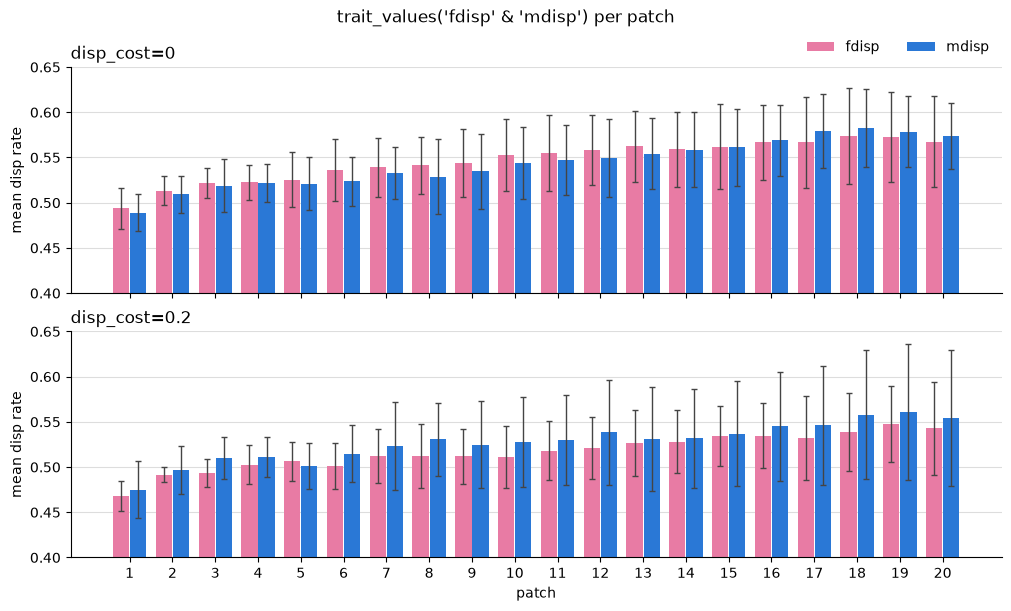

In [15]:
trait_colors = {'fdisp': '#e87ba4', 'mdisp': '#2a78d6'}                             # pink, blue
patch_numbers = np.arange(1, 21)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True, layout='constrained')
for ax, label in zip(axes, cost_settings):
    for offset, key in ((-0.2, 'fdisp'), (0.2, 'mdisp')):
        runs_by_patch = np.array(patch_disp_means[(label, key)])                       # 10 runs x 20 patches
        ax.bar(patch_numbers + offset, runs_by_patch.mean(axis=0), width=0.38, yerr=runs_by_patch.std(axis=0, ddof=1),
               color=trait_colors[key], ecolor='#444444', capsize=2, error_kw={'elinewidth': 1}, label=key)
    ax.set_title(label, loc='left')
    ax.set_ylabel('mean disp rate')
    ax.grid(axis='y', color='#dddddd', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[-1].set_xlabel('patch')
axes[-1].set_xticks(patch_numbers)
axes[-1].set_ylim(0.4, 0.65)                                                        # zoom in on the gradient: the bars do not start at 0
axes[0].legend(frameon=False, ncol=2, loc='lower right', bbox_to_anchor=(1, 1))
fig.suptitle("trait_values('fdisp' & 'mdisp') per patch")
plt.show()

**Take-home:** a range expansion sorts dispersal in space. 
- The first individuals to reach the empty patches are the strong dispersers, so dispersal rises from the founders' patch to the front, in both sexes and with or without a cost. 
- A dispersal cost does not remove this gradient; it lowers dispersal along the whole row.

In [ ]:
# recycle everything
for meta_obj in (asexual_meta, sexual_meta, sexual_range_meta, sexual_range_cost_meta):
    meta_obj.meta_clear_up_microsite_individuals()
    meta_obj.meta_clear_up_offspring_and_immigrant_pool()
    meta_obj.meta_clear_up_dormancy_pool()
for species_id, factory in species.items():
    assert factory.minted_num == factory.recycled_num, species_id                     # every individual it made is back in Nemo
    factory.purge_recycling_pool()

## 9. Summary

| Task | How |
|---|---|
| build a species with only disp | `indfactory(species_id, (), nemo_params, trait_keys=('fdisp', 'mdisp'))`, with `disp_mutation_rate` + `disp_mutation_mean` and at most one way to set the founders |
| fixed founders | `disp_init_rate`, or `disp_init_rate_fem` + `disp_init_rate_mal` |
| random founders | `disp_init_distribution` 'normal' (rows: `mdisp` first, then `fdisp`) or 'uniform' (+ any `disp_init_dist_params`) |
| read the dispersal rate | `individual.get_trait_value('fdisp')` / `('mdisp')`: float |
| read the alleles | `individual.get_trait_alleles('fdisp', 'get_allele_value')`: np.ndarray (1, 2), maternal then paternal |
| run it in MetaIBM | founders by hand, `method='neutral_uniform'`, `'asexual'` or `'sexual'` |
| let dispersal read the rates | a dispersal function with `use_disp_trait=True`; `is_rescale=True`: the same number, picked by v (scheme 2); `is_rescale=False`: each goes with v × m_ij (scheme 3); + `disp_cost`: death on the way (scheme 4); `sex_specific=True`: males read `mdisp` |